# 🔍 [AI 트랙] XAI 과제 — 내 모델은 어디를 보고 있을까?

<div style="background:#EFF4FF;border-left:6px solid #1E3A8A;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#1E3A8A">🎯 과제 목적</b><br>수업에서 배운 XAI 기법(Grad-CAM · LIME · SHAP)을 <b>직접 구현하고 적용</b>해 봅니다. 핵심은 코드를 완성하는 것이 아니라, <b>두 기법이 같은 이미지에 대해 내놓는 설명을 비교하고, 왜 그런 차이가 나는지 수업 내용(분류 축: Gradient vs Perturbation)으로 해석하는 것</b>입니다. 각자 학번 기반 시드로 <b>서로 다른 이미지</b>가 배정되므로, 남의 답을 복사하면 해석이 어긋납니다. 마지막에는 '설명 자체를 의심하는' sanity check까지 경험합니다.</div>


<div style="background:#FFF8E6;border-left:6px solid #B45309;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#B45309">✍️ 기술 블로그 연결 (꼭 읽어주세요!)</b><br>이 과제의 결과물은 여러분의 <b>논문 리뷰 기술 블로그</b>와 연결됩니다.<br><b>문제 1.3(Grad-CAM 클래스별 히트맵), 1.4~1.5(LIME 실험과 Grad-CAM 비교), 심화 2.2(sanity check)</b>의 결과 그래프와 여러분의 해석을 블로그에 옮겨 작성해 주세요. LIME 논문(Why Should I Trust You?) 리뷰에 '내가 직접 돌려본 LIME' 섹션이 들어가면 훨씬 좋은 글이 됩니다.</div>


<div style="background:#ECFDF5;border-left:6px solid #047857;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#047857">🤖 생성형 AI 사용 규칙</b><br>GPT/Claude 사용 <b>허용</b>합니다. 단 ① 에러 해결·문법 질문에 쓰는 것은 자유, ② <b>해석·비교·결론은 반드시 본인의 문장</b>으로 쓸 것 (실험 결과는 각자 다르므로 AI가 대신 써줄 수 없습니다), ③ <b>마지막 '3. 생성형 AI 활용 기록' 셀에 사용 내역과 대화 내용을 꼭 남길 것.</b> 기록 없이 AI 문체만 남은 답안은 감점됩니다.</div>

---
**제출물**: 이 노트북 완성본(.ipynb) 1개 — 모든 셀 실행 결과가 남아 있는 상태로 제출


## 📋 목차

| 번호 | 내용 | 난이도 |
|---|---|---|
| **0** | 환경 설정 — 라이브러리 · 내 시드 · 이미지 배정 | 🟢 |
| **1.1** | 사전학습 CNN 준비, 배정 이미지 예측 확인 | 🟢 |
| **1.2** | **Grad-CAM 직접 구현** (hook + α 계산 + ReLU) | 🔴 핵심 |
| **1.3** | 클래스별 히트맵 비교 실험과 해석 | 🟡 |
| **1.4** | LIME 적용 — 하이퍼파라미터 · 불안정성 실험 | 🟡 |
| **1.5** | Grad-CAM vs LIME 종합 비교 (서술) | 🟡 |
| **2.1** | (심화) SHAP — 표 데이터에서 Local↔Global | 🟡 선택 |
| **2.2** | (심화) Sanity Check — 설명을 의심하기 | 🔴 선택 |
| **3** | 생성형 AI 활용 기록 (**필수 제출**) | — |
| **4** | 회고 | — |


# 0. 환경 설정

<div style="background:#EFF4FF;border-left:6px solid #1E3A8A;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#1E3A8A">💡 시작 전에</b><br>런타임 유형을 <b>GPU</b>로 바꿔주세요 (상단 메뉴: 런타임 → 런타임 유형 변경 → T4 GPU). CPU로도 돌아가지만 LIME 실험(1.4)이 오래 걸립니다.<br>아래 설치·다운로드 셀은 처음 한 번만 실행하면 됩니다 (1~2분 소요).</div>

In [36]:
# 라이브러리 설치 (Colab 기본 환경에 없는 것만)
!pip -q install lime shap

# 실습용 이미지: ImageNet 1000개 클래스에서 클래스당 1장씩 모아둔 공개 저장소
!if [ ! -d imagenet-sample-images ]; then git clone -q --depth 1 https://github.com/EliSchwartz/imagenet-sample-images.git; fi
!ls imagenet-sample-images | head -3


README.md
gallery.md
n01440764_tench.JPEG
ls: stdout: Broken pipe


In [37]:
import os, random, copy
import numpy as np
import torch
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights
import matplotlib.pyplot as plt
from PIL import Image

if torch.backends.mps.is_available():
    device = torch.device("mps:0")
elif torch.cuda.is_available():
    device = torch.device("cuda:0")
else:
    device = torch.device("cpu:0")
print("사용 장치:", device)   # 'cuda'가 아니면 런타임 유형을 확인하세요


사용 장치: mps:0


In [38]:
# ──────────────────────────────────────────────
#  내 실험 조건 만들기 : 학번이 곧 나의 시드!
#  (같은 시드 = 같은 이미지 배정. 답안이 서로 다른 이유입니다)
# ──────────────────────────────────────────────
STUDENT_ID = 2333001   # TODO: 본인 학번을 숫자로 입력하세요 (예: 2271234)

assert STUDENT_ID != 0, "본인 학번을 입력해 주세요!"
SEED = STUDENT_ID % 10000
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f"나의 실험 시드: {SEED}")


나의 실험 시드: 3001


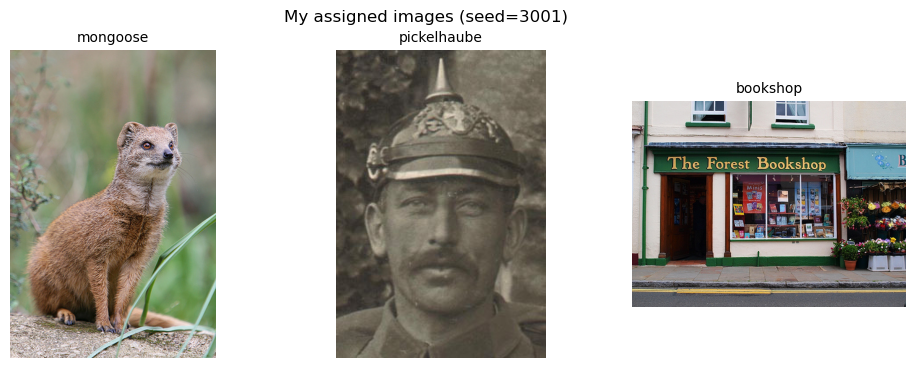

In [39]:
# 시드로 나만의 이미지 3장 배정받기
IMG_DIR = "imagenet-sample-images"
all_files = sorted(f for f in os.listdir(IMG_DIR) if f.upper().endswith(".JPEG"))
my_files = random.Random(SEED).sample(all_files, 3)

my_images = [Image.open(os.path.join(IMG_DIR, f)).convert("RGB") for f in my_files]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, name in zip(axes, my_images, my_files):
    ax.imshow(img); ax.axis("off")
    ax.set_title(name.split("_", 1)[-1].replace(".JPEG", ""), fontsize=10)
# 그래프 안 텍스트는 영문 사용 — Colab 기본 폰트에 한글이 없어 □로 깨집니다
plt.suptitle(f"My assigned images (seed={SEED})")
plt.show()


# 1. 필수 과제

## 1.1 사전학습 CNN 준비 — 모델은 내 이미지를 뭐라고 볼까?

ImageNet으로 학습된 **ResNet-18**을 불러와서, 배정받은 이미지 3장에 대한 **top-5 예측**을 확인합니다.
이 예측 결과가 이후 모든 문제의 출발점이 됩니다. *(이 단계는 코드가 거의 완성되어 있어요 — 주석 빈칸만 채우면 됩니다)*

<div style="background:#FFF8E6;border-left:6px solid #B45309;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#B45309">💬 주석 빈칸이란?</b><br>코드 중간의 <code># (빈칸 A) ...</code> 주석을 채우는 문제입니다. '내가 지금 어느 단계의 무엇을 하고 있는지'를 스스로 설명할 수 있어야 나중에 코드를 응용할 수 있기 때문에 넣었습니다. 한 줄이면 충분합니다!</div>

In [40]:
weights = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=weights).to(device).eval()   # (빈칸 A) .eval()을 호출하는 이유는? → 모델을 평가모드로 바꾸기 위해서이다. 평가모드에서는 batch norm에서 학습중에 저장된 평균과 분산을 이용한다.
categories = weights.meta["categories"]               # ImageNet 1000개 클래스 이름
preprocess = weights.transforms()                     # (빈칸 B) 이 전처리가 하는 일 두 가지는? → 전처리를 통해서 크기를 맞춰주며, 텐서 변환과 정규화를 진행한다.

def predict_probs(img_pil):
    """PIL 이미지 → 1000개 클래스 확률 (torch.Tensor, shape [1000])"""
    x = preprocess(img_pil).unsqueeze(0).to(device)
    with torch.no_grad():                             # (빈칸 C) 여기서 no_grad를 쓰는 이유는? → gradient 계산과 그 계산한 그래프를 기록을 저장하지 않기 위해서.
        logits = model(x)
    return F.softmax(logits, dim=1)[0].cpu()

for name, img in zip(my_files, my_images):
    probs = predict_probs(img)
    top5 = probs.topk(5)
    print(f"\n📷 {name}")
    for p, idx in zip(top5.values, top5.indices):
        print(f"   {categories[idx]:30s} {p*100:5.1f}%")



📷 n02137549_mongoose.JPEG
   mongoose                        81.2%
   weasel                          11.6%
   meerkat                          2.6%
   kit fox                          0.9%
   otter                            0.7%

📷 n03929855_pickelhaube.JPEG
   pickelhaube                     94.6%
   military uniform                 5.0%
   bearskin                         0.1%
   trombone                         0.0%
   shield                           0.0%

📷 n02871525_bookshop.JPEG
   bookshop                        84.3%
   tobacco shop                     8.2%
   toyshop                          4.0%
   bakery                           2.2%
   shoe shop                        0.4%


## 1.2 🔴 Grad-CAM 직접 구현 — 이 과제의 포인트

수업에서 배운 5단계 파이프라인을 그대로 코드로 옮깁니다. 라이브러리(`pytorch-grad-cam` 등)를 쓰지 않고
**hook으로 직접** 구현하는 것이 포인트입니다.

> **수업 복습** — ① Forward로 클래스 점수 $y^c$ 계산 → ② $y^c$를 마지막 conv의 feature map $A^k$까지 backward →
> ③ gradient를 공간 평균해 채널 가중치 $\alpha_k^c$ → ④ $\sum_k \alpha_k^c A^k$ 후 ReLU → ⑤ 입력 크기로 upsample

<div style="background:#FFF8E6;border-left:6px solid #B45309;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#B45309">💡 힌트</b><br>· hook은 '모델이 계산하는 중간 값을 몰래 저장하는 장치'입니다. forward hook은 활성값 A^k를, backward hook은 ∂y^c/∂A^k를 잡아둡니다 (둘 다 코드로 제공됨).<br>· <b>TODO 1</b>: gradient 텐서 shape은 [1, K, h, w]. 공간 축(h, w)에 대해 평균하면 α가 됩니다 → <code>mean(dim=?)</code><br>· <b>TODO 2</b>: α(shape [1,K,1,1])와 activations([1,K,h,w])를 곱해 채널 축으로 합한 뒤 ReLU → 수업의 2×2 손계산 예제와 같은 연산!<br>· 잘 됐는지 확인: 다음 셀의 시각화에서 히트맵이 물체 위에 얹혀야 정상입니다.</div>

In [41]:
class GradCAM:
    """수업의 5단계 파이프라인을 그대로 구현한 최소 Grad-CAM"""

    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None   # A^k  가 저장될 자리
        self.gradients = None     # ∂y^c/∂A^k 가 저장될 자리
        # hook 등록: forward/backward 때 중간값을 가로채 저장
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out.detach()          # shape [1, K, h, w]

    def _save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()    # shape [1, K, h, w]

    def __call__(self, x, class_idx=None):
        # ① Forward — 클래스 점수 계산
        self.model.zero_grad()
        logits = self.model(x)
        if class_idx is None:
            class_idx = logits.argmax(dim=1).item()

        # ② Backward — 선택한 클래스 점수만 미분
        score = logits[0, class_idx]
        score.backward()

        # ③ 채널 가중치 α_k^c 계산
        # (빈칸 D) 이 줄이 수업 슬라이드의 어떤 수식에 해당하는지 쓰세요 → 수업슬라이드 27페이지의 채널 가중치 계산을 구하는 수식에 해당된다.
        alpha = self.gradients.mean(dim=(2,3),keepdim=True)   # TODO 1: self.gradients 를 공간 축에 대해 평균 (keepdim=True 권장)

        # ④ 가중합 + ReLU
        # (빈칸 E) ReLU를 마지막에 적용하는 이유는? → 목표 클래스의 점수를 높이는 데 양수 값만 유지하기 위해서이다.
        cam = F.relu((alpha * self.activations).sum(dim=1))    # TODO 2: (alpha * self.activations)를 채널 축으로 합한 뒤 F.relu

        # ⑤ 정규화 + 입력 크기로 upsample (완성되어 있음)
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        cam = F.interpolate(cam.unsqueeze(0), size=x.shape[-2:],
                            mode="bilinear", align_corners=False)
        return cam[0, 0].cpu().numpy(), class_idx

# 마지막 conv 블록(layer4의 마지막 BasicBlock)에 hook을 겁니다
gradcam = GradCAM(model, model.layer4[-1])
print("GradCAM 준비 완료")

GradCAM 준비 완료


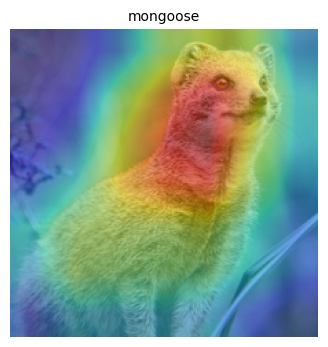

In [42]:
# 시각화 도우미 (완성 코드 — 그대로 실행)
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225])[:, None, None]

def to_numpy_img(x):
    """정규화된 텐서[3,H,W] → 화면 표시용 numpy[H,W,3]"""
    return (x.cpu() * IMAGENET_STD + IMAGENET_MEAN).clamp(0, 1).permute(1, 2, 0).numpy()

def show_gradcam(img_pil, class_idx=None, ax=None, title=None):
    x = preprocess(img_pil).unsqueeze(0).to(device)
    cam, used_idx = gradcam(x, class_idx)
    if ax is None:
        _, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(to_numpy_img(x[0])); ax.imshow(cam, cmap="jet", alpha=0.45)
    ax.axis("off"); ax.set_title(title or categories[used_idx], fontsize=10)
    return used_idx

# 동작 확인: 첫 번째 배정 이미지의 top-1 히트맵
show_gradcam(my_images[0])
plt.show()


## 1.3 실험 — 같은 이미지, 다른 클래스로 미분하면?

Grad-CAM의 매력은 **class-discriminative**, 즉 "어느 클래스 입장에서 보는가"를 우리가 고를 수 있다는 점이었죠
(수업의 Cat/Dog 그림). 내 이미지 3장 각각에 대해 **top-1 클래스 히트맵과 top-2 클래스 히트맵**을 나란히 그려 비교하세요.

**해야 할 일**
1. 아래 셀을 완성해 3장 × (원본 | top-1 CAM | top-2 CAM) 그리드를 그린다
2. 그림 아래 답안 셀에 해석을 쓴다 — *top-1과 top-2 히트맵이 다른 곳을 비추는 이미지가 있나요? 그 이유는 무엇일까요?
모델이 엉뚱한 곳(배경 등)을 보는 경우가 있다면 그것은 무엇을 시사하나요?*

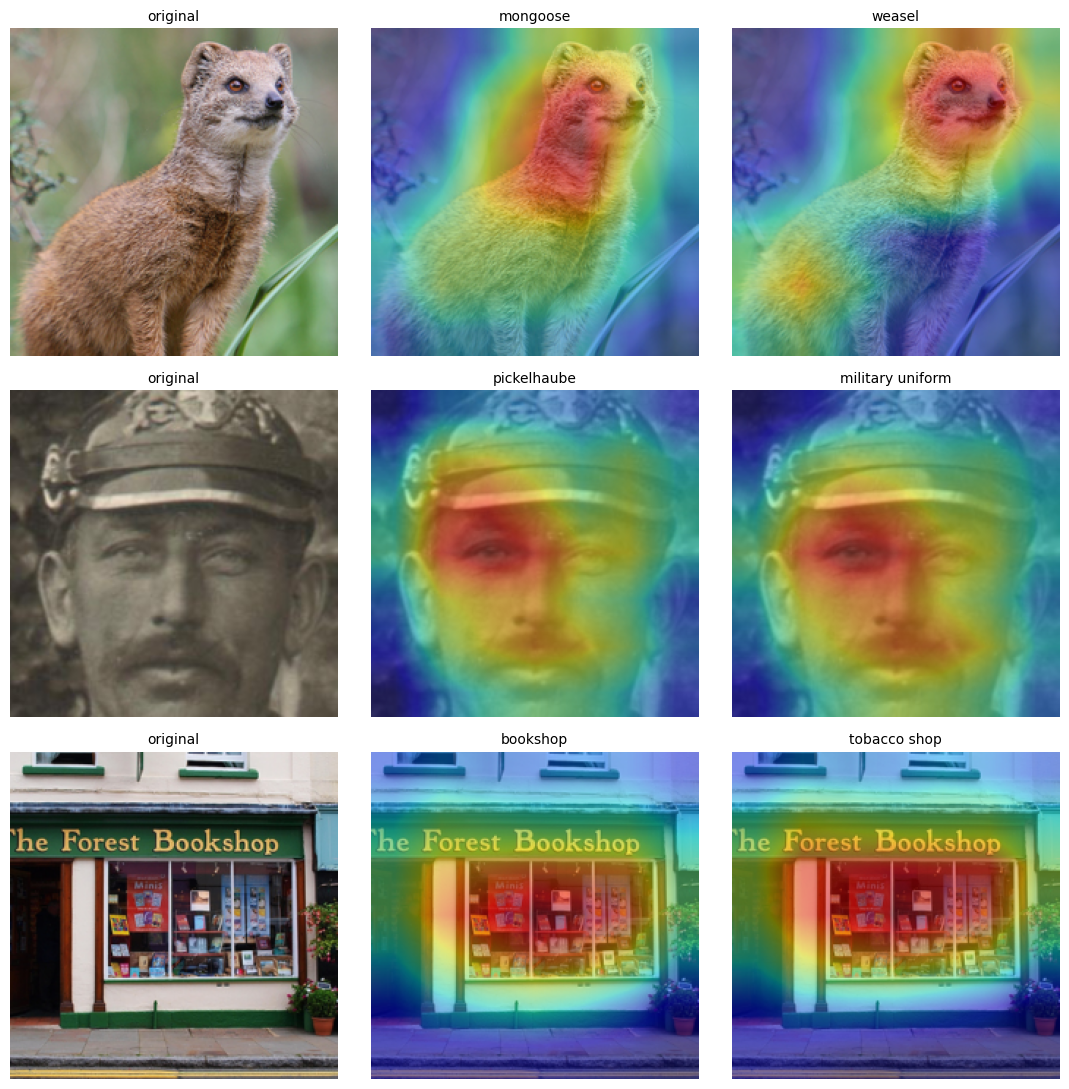

In [43]:
fig, axes = plt.subplots(3, 3, figsize=(11, 11))
for r, (name, img) in enumerate(zip(my_files, my_images)):
    probs = predict_probs(img)
    top2 = probs.topk(2).indices.tolist()

    x = preprocess(img).unsqueeze(0).to(device)
    axes[r, 0].imshow(to_numpy_img(x[0])); axes[r, 0].axis("off")
    axes[r, 0].set_title("original", fontsize=10)   # 그래프 안 텍스트는 영문 (Colab 한글 폰트 미지원)

    show_gradcam(img, class_idx=top2[0], ax=axes[r,1])
    show_gradcam(img, class_idx=top2[1], ax=axes[r,2])

    # TODO: top-1 클래스의 히트맵을 axes[r, 1]에,
    #       top-2 클래스의 히트맵을 axes[r, 2]에 그리세요 (show_gradcam 활용)
    # (빈칸 F) top-2 히트맵을 그릴 때 class_idx 인자에 무엇을 넣어야 하나요? → top2[1]을 넣어야한다. 왜냐하면, top-2 클래스 인덱스가 top2에 저장되어있다.
    
plt.tight_layout(); plt.show()


<div style="background:#ECFDF5;border-left:6px solid #047857;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#047857">📝 1.3 답안 (여기에 작성)</b><br>· top-1 vs top-2 히트맵 비교에서 발견한 것:<br>top-1, top-2의 히트맵을 통해서 grad-cam이 클래스별로 중요 영역을 시각화 하였다. 첫번째 mongoose는 목과 밑부분에, weasel은 머리쪽에 집중이 되어 있다. 두번째와 세번째 이미지를 보면 top-1과 top-2 히트맵의 차이가 거의 보이지는 않았다. <br>· 그 차이/유사가 생긴 이유(모델 구조·클래스 관계 관점):<br>왜냐하면, top-1과 top-2는 feature map A^k는 같지만 클래스별로 계산되는 가중치가 α_k^c만 다르기 때문에 다음과 같이 유사하게 나타나는 것 같다. 2, 3번은 두 클래스가 중요도 가중치를 높게 주는 특징이 비슷해서 히트맵도 비슷하게 나온 것 같다. <br>· 배경 등 엉뚱한 곳을 보는 경우가 있었다면 그 의미: 위 히트맵을 보면 엉뚱한 부분을 보는 경우는 없었던것 같다.</div>

## 1.4 LIME — 같은 이미지를 Perturbation으로 설명하면?

이번에는 **모델 내부를 전혀 모른 채** superpixel을 켜고 끄는 LIME으로 같은 이미지를 설명합니다.

**해야 할 일**
1. 아래 코드로 첫 번째 배정 이미지의 LIME 설명을 만든다 *(1~2분 걸립니다 — 수업에서 왜 느리다고 했는지 떠올려 보세요!)*
2. `num_features`를 **3 → 10**으로 바꿔 다시 실행하고 두 결과를 비교한다
3. **같은 조건으로 한 번 더** 실행해 결과가 달라지는지(불안정성) 관찰한다

<div style="background:#FFF8E6;border-left:6px solid #B45309;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#B45309">💡 파라미터 읽는 법</b><br><code>num_samples</code> = 만들 변형 샘플 수(= 모델에 질의하는 횟수), <code>num_features</code> = 설명에 남길 superpixel 조각 수 (수업 목적함수의 Ω(g) — 복잡도 제한에 해당)</div>

In [44]:
from lime import lime_image
from skimage.segmentation import mark_boundaries

def batch_predict(images):
    """LIME이 부르는 예측 함수: numpy 이미지 배치 → 클래스 확률 배치"""
    batch = torch.stack([preprocess(Image.fromarray(im)) for im in images]).to(device)
    with torch.no_grad():
        logits = model(batch)
    return F.softmax(logits, dim=1).cpu().numpy()

target_img = np.array(my_images[0].resize((224, 224)))
explainer = lime_image.LimeImageExplainer(random_state=SEED)

explanation = explainer.explain_instance(
    target_img,
    batch_predict,        # LIME은 이 함수를 '질의'만 함 — model-agnostic의 실체!
    top_labels=1,
    num_samples=1000,     # 변형 샘플 1000개 = 추론 1000번
)
print("LIME 설명 생성 완료 — top 클래스:", categories[explanation.top_labels[0]])


100%|██████████| 1000/1000 [00:02<00:00, 364.88it/s]

LIME 설명 생성 완료 — top 클래스: mongoose


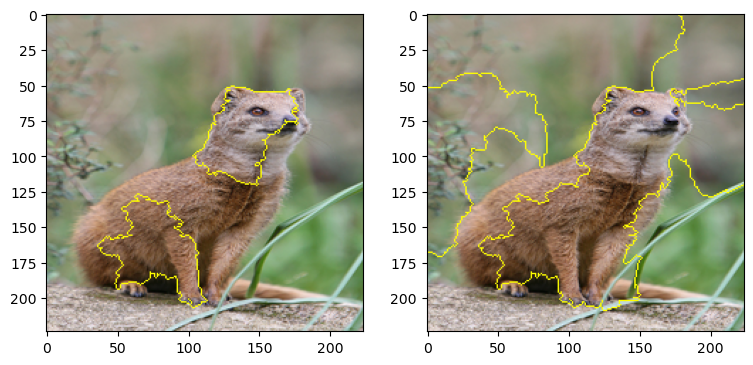

In [ ]:
# num_features 를 3, 10 으로 바꿔 두 번 그려 비교하세요
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, k in zip(axes, [3, 10]):
    temp, mask = explanation.get_image_and_mask(label=explanation.top_labels[0], positive_only=True, num_features=k, hide_rest=False)
    ax.imshow(mark_boundaries(temp/255.0, mask))
    # TODO: explanation.get_image_and_mask(...)를 호출해
    #       positive_only=True, num_features=k, hide_rest=False 로 마스크를 얻고
    #       mark_boundaries(temp/255.0, mask) 를 ax.imshow 로 그리세요
    # (빈칸 G) num_features가 수업 목적함수의 어떤 항에 해당? → 복잡도 패널티
    pass
plt.show()


100%|██████████| 1000/1000 [00:02<00:00, 352.71it/s]


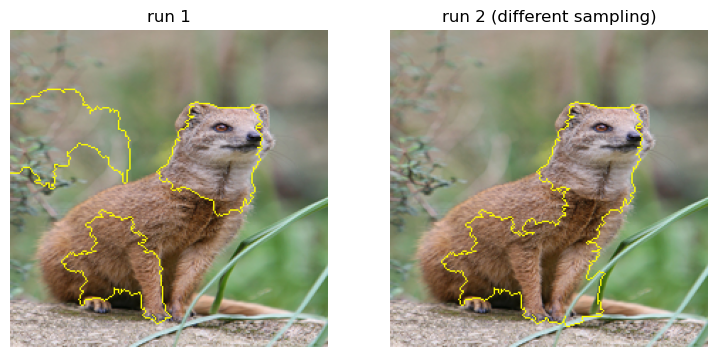

In [ ]:
# 불안정성 실험: random_state를 바꿔 같은 설명을 한 번 더
explainer2 = lime_image.LimeImageExplainer(random_state=SEED + 1)
explanation2 = explainer2.explain_instance(target_img, batch_predict,
                                           top_labels=1, num_samples=1000)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, (exp, t) in zip(axes, [(explanation, "run 1"), (explanation2, "run 2 (different sampling)")]):
    temp, mask = exp.get_image_and_mask(exp.top_labels[0], positive_only=True,
                                        num_features=5, hide_rest=False)
    ax.imshow(mark_boundaries(temp / 255.0, mask)); ax.axis("off"); ax.set_title(t)
plt.show()
# 두 실행의 결과가 완전히 같은가요? 다르다면 어느 정도 다른가요? → 아래 답안 셀에 기록
## 위 결과를 보면 두 실행 결과는 완전히 같지 않고, 비슷하면서 다르다. 두 실행 결과를 보면 머리,목 , 다리 부근을 모두 선택했다.
## 하지만, run 1에서는 왼쪽 덤블 영역을 선택했고, run2에서는 가슴과 몸족을 선택했다.


## 1.5 종합 비교 — Grad-CAM vs LIME (서술형)

1.3과 1.4의 결과를 옆에 놓고, 아래 표의 빈칸을 **본인의 실험 결과 근거**를 들어 채우세요.
"수업에서 배웠으니까"가 아니라 **"내 실험에서 이렇게 나왔으니까"**로 쓰는 것이 이 문제의 전부입니다.

| 비교 항목 | Grad-CAM (내 결과) | LIME (내 결과) |
|---|---|---|
| 걸린 시간 (체감) | 히트백 6장이 0.5초 만에 끝났다. forward,backward 한 번이라 빠르다.| 이미지 1장을 설명하는 데 샘플 1000개를 추론하느라 약 2~3초가 걸렸다.|
| 설명의 형태·해상도 | 히트맵이며, 중요도의 정도가 색의 진하기로 표현되어 있다. | 슈퍼픽셀 단위로 노란 경계선으로 나타나 있다.|
| 재실행 시 안정성 | 무작위 요소가 없어 같은 입력이면 같은 히트맵이 나온다. | 모두 머리·목과 몸 아래쪽은 같았지만, run 1은 왼쪽 위 배경, run 2는 가슴쪽이 추가로 선택되어 하위 조각이 달라졌다.|
| 모델 내부 접근이 필요했나? | 필요했다. 왜냐하면, 모델 내부의 정방향 연산 때 뱉어낸 결과물인 A_k를 가져와서 계산에 이용해야한다. | 원본 모델의 입출력만 사용하므로 내부 구조에 접근할 필요가 없다. 

<div style="background:#ECFDF5;border-left:6px solid #047857;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#047857">📝 1.5 답안 (여기에 작성)</b><br>· 위 표를 채운 뒤:<br>· 두 기법의 차이가 생기는 근본 원인 (Gradient vs Perturbation 축으로 설명):<br>GRAD-CAM은 gradient 기반이다. forward와 backward하여 채널 가중치를 계산하고 이를 바탕으로 히트맵을 만든다. 반면, LIME은 perturbation 기반이다.이미지를 superpixel로 분할하고 영역을 가린 변형 샘플로 국소 대리 모델 학습을 진행한다. <br>· 만약 ①모델 코드를 볼 수 없는 외부 API ②내가 학습시킨 CNN, 각각의 상황에서 어떤 기법을 쓸지와 이유: 모델 코드를 볼 수 없을때는 LIME을 사용하고, 내가 학습시킨 CNN 상황에서는 Grad-Cam을 선택한다. LIME은 모델 내부 접근이 필요없고, 반면 Grad-CAM은 내내부에 접근할 수 있으니 그 제약이 문제가 안 된다..</div>

# 2. 심화 과제 (선택 — 둘 중 하나만 해도 됩니다)

## 2.1 SHAP — 표 데이터에서 Local ↔ Global 오가기

이미지에서 벗어나 SHAP이 가장 빛나는 **표 데이터 + 트리 모델** 조합을 경험합니다.
캘리포니아 주택 가격 데이터로 RandomForest를 학습하고 **TreeSHAP**으로 설명합니다.

**해야 할 일** — ① beeswarm(=summary) plot으로 **전역(Global)** 중요도를 읽고 ② waterfall plot으로 **개별 예측(Local)** 하나를 분해한 뒤
③ 수업에서 배운 **Local Accuracy**(기여도 합 = 예측값)를 코드로 직접 검증하세요.

R^2 (test): 0.767


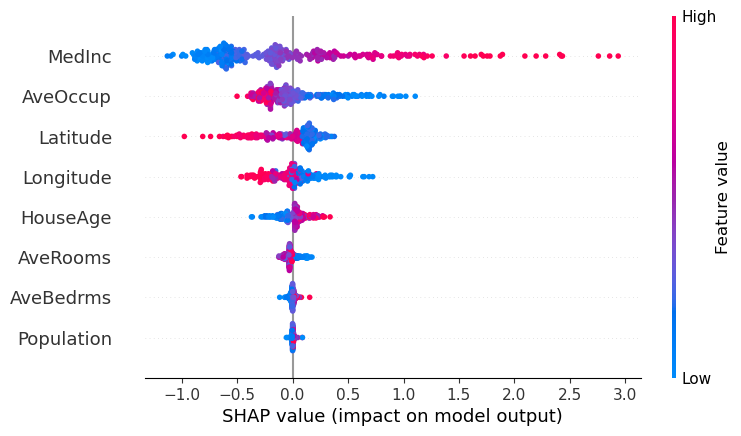

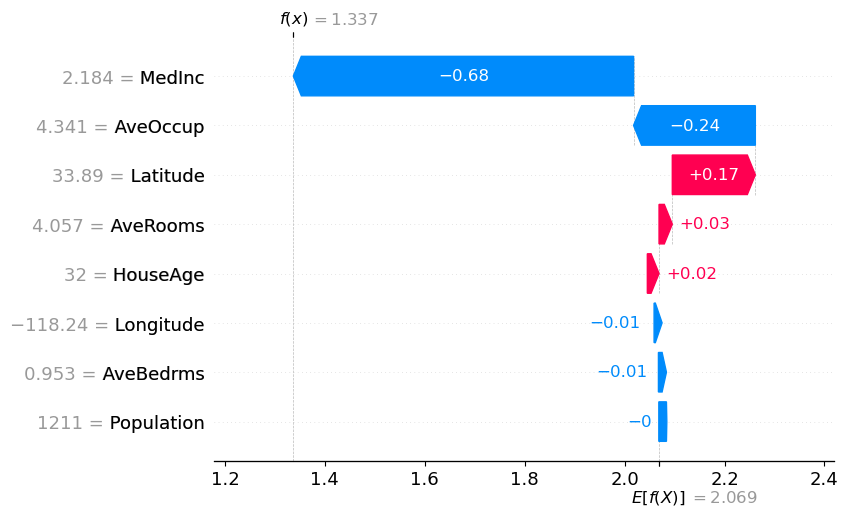

2.4424906541753444e-15


In [48]:
import shap
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

data = fetch_california_housing(as_frame=True)
X, y = data.data, data.target
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)

rf = RandomForestRegressor(n_estimators=100, max_depth=8,
                           random_state=SEED, n_jobs=-1).fit(X_tr, y_tr)
print("R^2 (test):", round(rf.score(X_te, y_te), 3))

# TreeSHAP: 트리 구조를 이용해 정확한 Shapley 값을 빠르게 계산
explainer = shap.TreeExplainer(rf)
sv = explainer(X_te.iloc[:300])

shap.plots.beeswarm(sv)          # Global: 전체 경향
shap.plots.waterfall(sv[0])      # Local: 첫 번째 집 한 채의 분해

# TODO: Local Accuracy 검증 —
pred=rf.predict(X_te.iloc[[0]])[0]
shap_sum =  sv[0].values.sum()+sv[0].base_values
print(abs(pred - shap_sum))
#   sv[0].values 의 합 + sv[0].base_values 가 rf.predict(첫 샘플) 과 (거의) 같은지 확인
# (빈칸 H) base_values는 수업 force plot 그림의 무엇에 해당? → 출발점?기준점?이다.


<div style="background:#ECFDF5;border-left:6px solid #047857;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#047857">📝 2.1 답안 (여기에 작성)</b><br>· beeswarm에서 가장 중요한 feature 2개와, 그 값이 클 때 집값을 올리는지/내리는지:<br>가장 중요한 feature은 MedInc,AveOccup이다. MedInc 값이 클때 집값이 올라가고, AveOccup이 클 때에는 집값이 내려간다.<br>· waterfall의 첫 샘플: 예측을 가장 크게 움직인 feature와 방향:<br>기준값은 2.069에서 최종 예측은 1.337이다. 가장 크게 움직인 feature은 MedInc이고, 예측을 낮췄다.<br>· Local Accuracy 검증 결과: 2.4424906541753444e-15</div>

## 2.2 Sanity Check — 이 설명, 정말 모델을 보고 있나?

수업 3부에서 "설명 기법 자체도 검증 대상"이라고 했습니다 (Adebayo et al., 2018).
그 검증을 직접 해봅니다: **모델의 뒷부분 가중치를 랜덤으로 망가뜨렸을 때, Grad-CAM 히트맵이 함께 망가지는지** 확인합니다.

> 만약 모델을 망가뜨렸는데도 히트맵이 그대로라면 → 그 히트맵은 모델의 판단이 아니라
> 이미지의 윤곽선을 그리고 있었다는 뜻 (= 설명으로서 실격!)

In [ ]:
# 모델 복사 후 layer4와 fc의 가중치를 랜덤화
model_broken = copy.deepcopy(model)
for module in [model_broken.layer4, model_broken.fc]:
    for p in module.parameters():
        torch.nn.init.normal_(p, std=0.02)
model_broken.eval()

gradcam_broken = GradCAM(model_broken, model_broken.layer4[-1])

# TODO: 첫 번째 배정 이미지에 대해
#   ① 정상 모델의 히트맵 ② 망가진 모델의 히트맵 을 나란히 그리고 비교하세요
# (빈칸 I) 이 실험에서 히트맵이 '달라져야' 좋은 설명 기법인 이유 → ____________


# 3. 생성형 AI 활용 기록 (⚠️ 필수 제출)

<div style="background:#FEF2F2;border-left:6px solid #B91C1C;color:#1F2937;padding:14px 18px;border-radius:6px;line-height:1.7"><b style="color:#B91C1C">반드시 작성해 주세요</b><br>이 셀이 비어 있으면 감점입니다. AI를 안 썼다면 '사용하지 않음'이라고 쓰면 됩니다. 솔직한 기록은 감점 사유가 아니며, 오히려 어떻게 도구를 썼는지가 평가 대상입니다.</div>

**작성 양식:**

### ① 핵심 대화 내역 붙여넣기

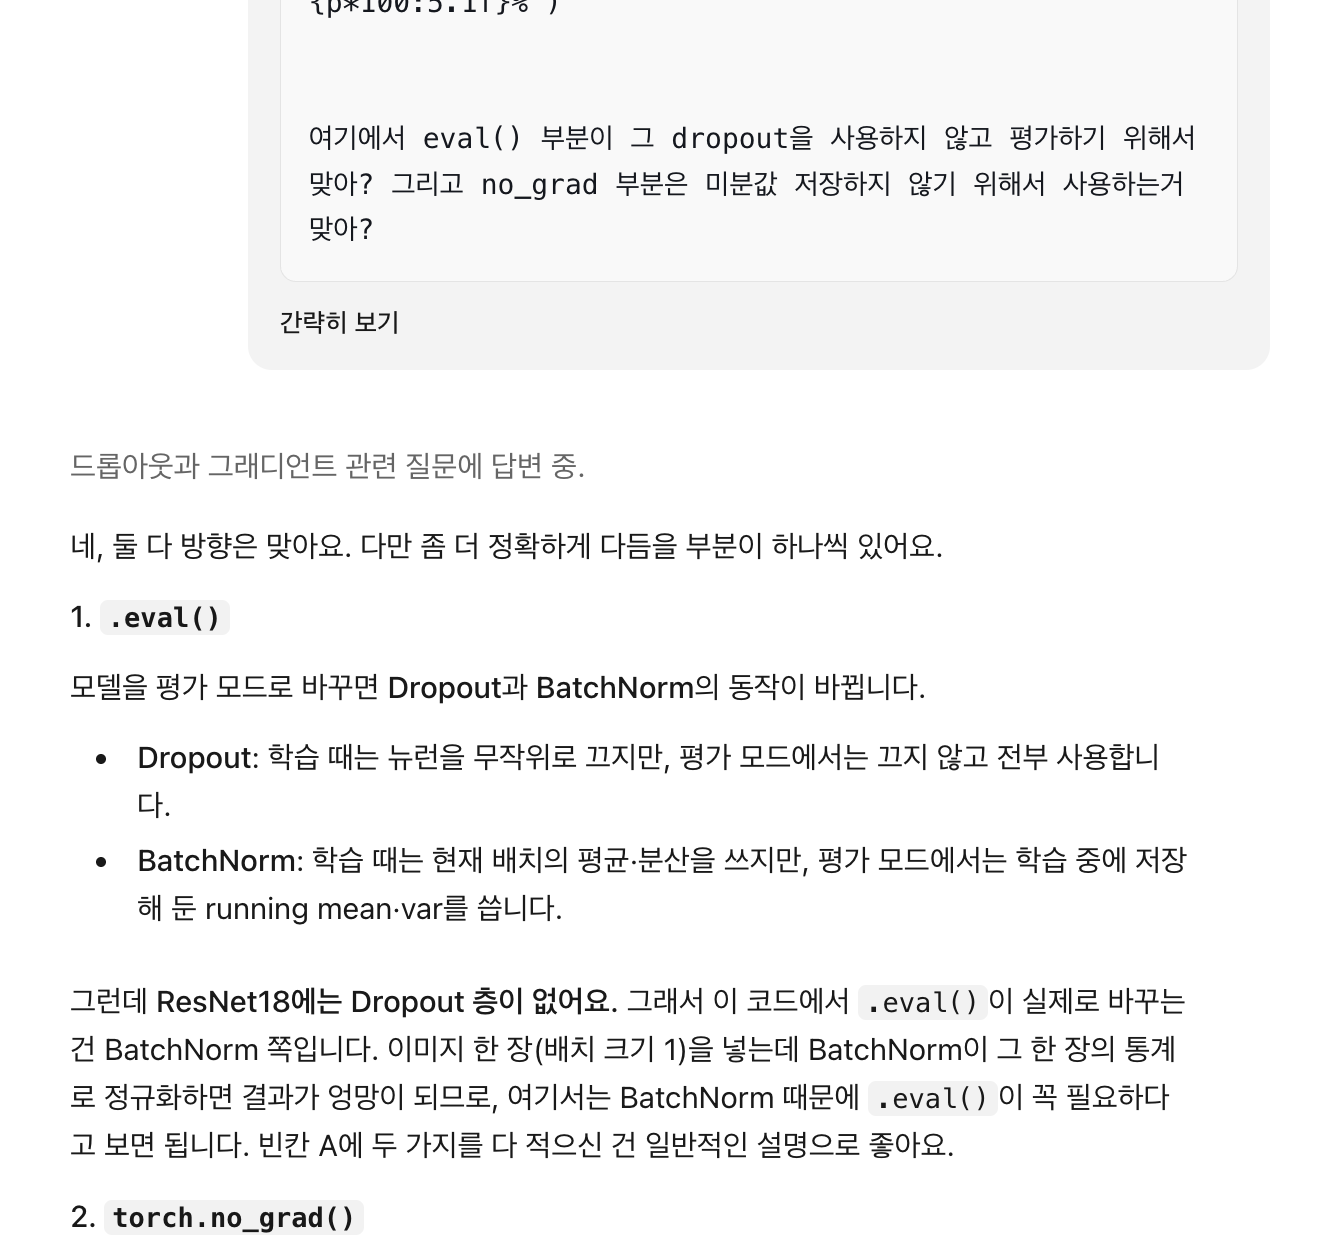
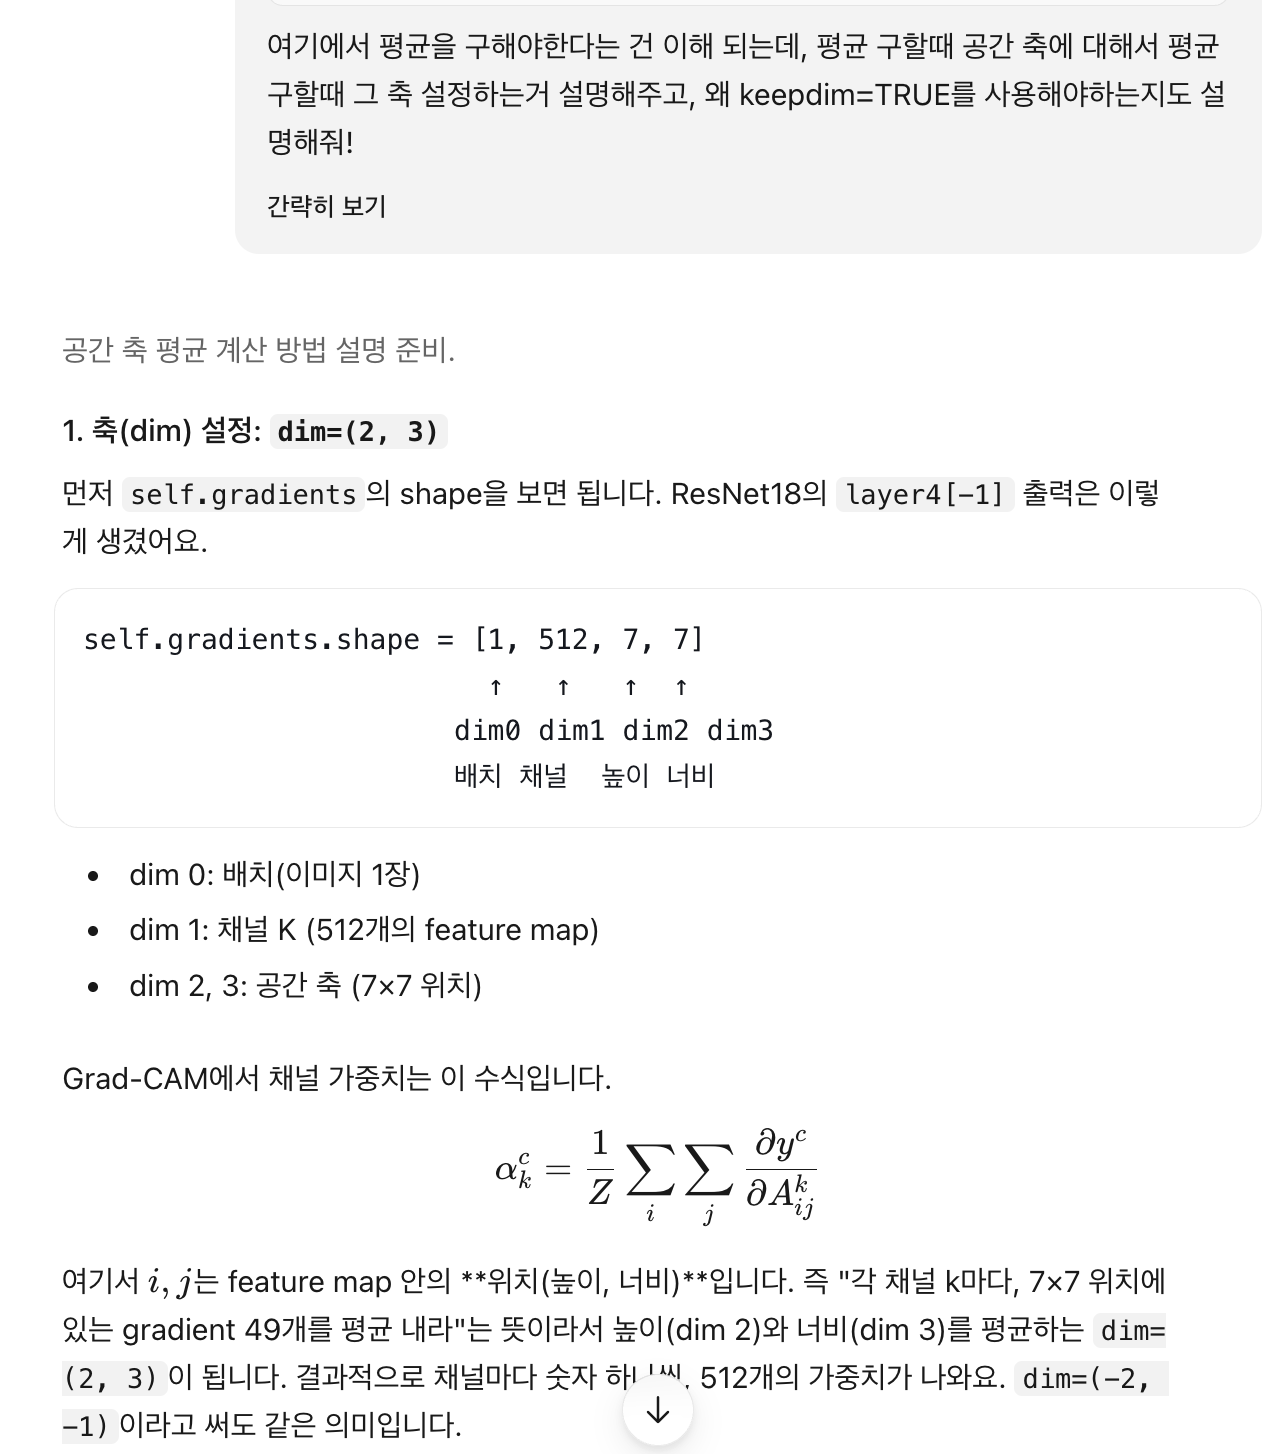



### ② AI 답변을 그대로 쓰지 않고 직접 판단/수정한 부분
- (예) GPT가 알려준 코드는 `register_backward_hook`(deprecated)이어서 문서를 찾아 `full_backward_hook`으로 바꿈
- 없습니다. Claude에서 local accuracy를 예측값으로 알려줘서 예측값과 실제 값을 이용해서 따로 계산함.

# 4. 회고

한 학기 뒤의 나에게 남기는 메모라고 생각하고 가볍게 적어 주세요.

- **가장 신기했던 결과** 하나: 모델은 94.6%로  pickelhaube를 맞혔는데, 히트맵에서는 투구보다는 주로 눈 주변 얼굴 보고 맞췄어서, 정답을 맞히기는 하였지만, 제대로 된 근거는 아니었던 것 같다.
- 수업 내용 중 과제를 하며 **비로소 이해된 것**: 과제를 하면서 사실 XAI에 대표적인 기법들에 뭐가 있는지 알고 있엇는데, 이것을 막상 해보니까 이해한거와 실습한게 다랐다. 그렇지만, 과제를 하면 Grad-Cam이 작동하는 방식을 코드로 보면서 조금 더 확실히 이해된 것 같다.
---
<div style="text-align:center;opacity:.75">수고했습니다! 🎉 — 모든 셀의 실행 결과가 남아 있는지 확인한 뒤 .ipynb로 제출해 주세요</div>